# Fil rouge ProtAnnotML · 6 — Passer à l'échelle : GPU 6 Go, V100, H100 sur Jean Zay, puis mise en service

> **Objectif** : savoir **avant de lancer** si un entraînement tient en mémoire et combien de temps il prendra, choisir la bonne configuration pour chaque machine (ton GPU de 6 Go, le V100 du serveur, les H100 de Jean Zay), écrire des scripts Slurm robustes (nœuds sans Internet, limite de temps, reprise), rendre les résultats reproductibles, et livrer l'outil : ligne de commande, service web, sortie compatible AIRR, fiche de modèle.

| | |
|---|---|
| **Durée estimée** | 2 h |
| **Prérequis** | Fil rouge 4 ; modules 14 (mémoire LoRA/QLoRA) |
| **Librairies** | `numpy`, `matplotlib` (calculs exécutés ici) ; `torch`, `fastapi`, `uvicorn` (scripts) |

**Plan**

1. Budget mémoire : ce qui tient où
2. Budget temps : combien d'heures GPU
3. Le bon réglage pour chaque machine
4. Jean Zay : scripts Slurm, nœuds hors ligne, reprise
5. Reproductibilité
6. Livrer l'outil : ligne de commande, service, sortie AIRR
7. Fiche de modèle et organisation du projet
8. Récapitulatif et exercices

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
ROOT = Path.cwd().parent / "projet_protannotml"
sys.path.insert(0, str(ROOT))

## 1. Budget mémoire : ce qui tient où

La mémoire d'entraînement se décompose en trois parts :

- **états du modèle** : en affinage complet avec AdamW et précision mixte (poids maîtres en float32), compter ~16 octets par paramètre (poids 4 + gradients 4 + deux moments d'Adam 8). Avec LoRA, les poids gelés ne coûtent que leur stockage (4 octets en float32, 2 en bf16), et les états d'optimisation ne portent que sur les adaptateurs (quelques millions de paramètres) ;
- **activations** : d'après Korthikanti et al. (2022), une couche de Transformer conserve environ $s\,b\,h\,(34 + 5\,a\,s/h)$ octets en 16 bits ($s$ longueur, $b$ lot, $h$ dimension, $a$ têtes). Le terme $5as/h$ correspond aux scores d'attention ; il disparaît presque avec une attention « fusionnée » (SDPA / FlashAttention). Avec le *gradient checkpointing*, on ne garde que l'entrée de chaque couche ($2sbh$ octets) plus les activations d'une seule couche pendant le recalcul ;
- **surcoût** : contexte CUDA, fragmentation de l'allocateur : on garde ~1 Go et 10 % de marge.

In [2]:
ESM2 = pd.DataFrame([
    ("esm2_t6_8M", 8e6, 6, 320, 20), ("esm2_t12_35M", 35e6, 12, 480, 20), ("esm2_t30_150M", 150e6, 30, 640, 20),
    ("esm2_t33_650M", 650e6, 33, 1280, 20), ("esm2_t36_3B", 3e9, 36, 2560, 40), ("esm2_t48_15B", 15e9, 48, 5120, 40),
], columns=["model", "params", "layers", "hidden", "heads"])
GPUS = {"GPU 6 Go": 6, "V100 16 Go": 16, "V100 32 Go": 32, "H100 80 Go": 80}


def train_memory_gb(row, batch, seq, mode="full", checkpointing=False, fused_attention=True, lora_params=4e6):
    P, L, h, a = row.params, row.layers, row.hidden, row.heads
    states = 16 * P if mode == "full" else 4 * P + 16 * lora_params
    per_layer = seq * batch * h * (34 + (0 if fused_attention else 5 * a * seq / h))
    acts = (2 * seq * batch * h * L + per_layer) if checkpointing else per_layer * L
    return (states + acts) / 1e9


def fits(gb, gpu_gb):
    return gb <= 0.9 * gpu_gb - 1.0

rows = []
for r in ESM2.itertuples():
    for mode, ckpt in [("full", False), ("full", True), ("lora", True)]:
        gb = train_memory_gb(r, batch=8, seq=256, mode=mode, checkpointing=ckpt)
        rows.append(dict(model=r.model, setting=f"{mode}{' + ckpt' if ckpt else ''}", GB=round(gb, 1),
                         **{g: "oui" if fits(gb, v) else "-" for g, v in GPUS.items()}))
print("Training memory, batch 8 x 256 residues, AdamW, mixed precision, fused attention")
print(pd.DataFrame(rows).to_string(index=False))

Training memory, batch 8 x 256 residues, AdamW, mixed precision, fused attention
        model     setting    GB GPU 6 Go V100 16 Go V100 32 Go H100 80 Go
   esm2_t6_8M        full   0.3      oui        oui        oui        oui
   esm2_t6_8M full + ckpt   0.2      oui        oui        oui        oui
   esm2_t6_8M lora + ckpt   0.1      oui        oui        oui        oui
 esm2_t12_35M        full   1.0      oui        oui        oui        oui
 esm2_t12_35M full + ckpt   0.6      oui        oui        oui        oui
 esm2_t12_35M lora + ckpt   0.3      oui        oui        oui        oui
esm2_t30_150M        full   3.7      oui        oui        oui        oui
esm2_t30_150M full + ckpt   2.5      oui        oui        oui        oui
esm2_t30_150M lora + ckpt   0.8      oui        oui        oui        oui
esm2_t33_650M        full  13.3        -        oui        oui        oui
esm2_t33_650M full + ckpt  10.7        -        oui        oui        oui
esm2_t33_650M lora + ckpt   2.9

Lecture pratique (ce sont des bornes **basses** : ajoute les tampons temporaires, notamment les logits de la tête positions, et la fragmentation) :
- sur **6 Go** : ESM-2 150M en affinage complet (≈ 3,7 Go estimés), ou 650M en LoRA avec checkpointing (≈ 2,9 Go estimés, serré en pratique) ; c'est la machine du **test rapide**, des itérations sur sous-ensembles et de l'inférence ;
- sur **V100** : 650M en affinage complet (≈ 13 Go : à la limite sur un 16 Go, confortable sur un 32 Go), ou 3B en LoRA (≈ 13 Go) ;
- sur **H100 80 Go** : 3B en affinage complet (≈ 54 Go), et même 15B en LoRA (≈ 61 Go). Le 15B en affinage complet demanderait un partitionnement des états (FSDP / ZeRO) sur plusieurs GPU, et il n'est **pas** justifié pour ProtAnnotML (voir AMPLIFY dans la liste de lecture : la qualité des données compte plus que la taille).

Ce calcul est une estimation : mesure toujours le pic réel avec `torch.cuda.max_memory_allocated()` sur quelques pas avant de lancer un long entraînement.

## 2. Budget temps : combien d'heures GPU

Un entraînement coûte environ $6\,N\,D$ FLOP ($N$ paramètres entraînés à travers, $D$ tokens vus), $8\,N\,D$ avec checkpointing (un forward recalculé). Le temps dépend du **taux d'utilisation** réel du GPU (MFU, *model FLOPs utilization*), typiquement 30 à 45 % pour des séquences courtes bien regroupées par longueur. Pics constructeur en 16 bits denses : V100 SXM2 125 TFLOP/s, H100 SXM 989 TFLOP/s ; pour la carte de 6 Go, on prend 25 TFLOP/s (ordre de grandeur, à ajuster à ton modèle de carte).

In [3]:
PEAK_TFLOPS = {"GPU 6 Go": 25, "V100": 125, "H100": 989}


def hours(params, tokens, peak_tflops, n_gpus=1, mfu=0.35, checkpointing=False):
    flops = (8 if checkpointing else 6) * params * tokens
    return flops / (peak_tflops * 1e12 * mfu * n_gpus) / 3600

workloads = {"DAPT : 2 M séquences x 130 résidus x 2 époques": 2e6 * 130 * 2,
             "Affinage : 200 k séquences x 250 résidus x 8 époques": 2e5 * 250 * 8}
rows = []
for wname, tokens in workloads.items():
    for model, P in [("35M", 35e6), ("150M", 150e6), ("650M", 650e6), ("3B", 3e9)]:
        rows.append(dict(workload=wname.split(" :")[0], model=model,
                         **{"6 Go": f"{hours(P, tokens, 25, checkpointing=True):.1f} h",
                            "1 x V100": f"{hours(P, tokens, 125, checkpointing=True):.1f} h",
                            "4 x H100": f"{hours(P, tokens, 989, n_gpus=4):.2f} h"}))
print(pd.DataFrame(rows).to_string(index=False))

workload model    6 Go 1 x V100 4 x H100
    DAPT   35M   4.6 h    0.9 h   0.02 h
    DAPT  150M  19.8 h    4.0 h   0.09 h
    DAPT  650M  85.8 h   17.2 h   0.41 h
    DAPT    3B 396.2 h   79.2 h   1.88 h
Affinage   35M   3.6 h    0.7 h   0.02 h
Affinage  150M  15.2 h    3.0 h   0.07 h
Affinage  650M  66.0 h   13.2 h   0.31 h
Affinage    3B 304.8 h   61.0 h   1.44 h


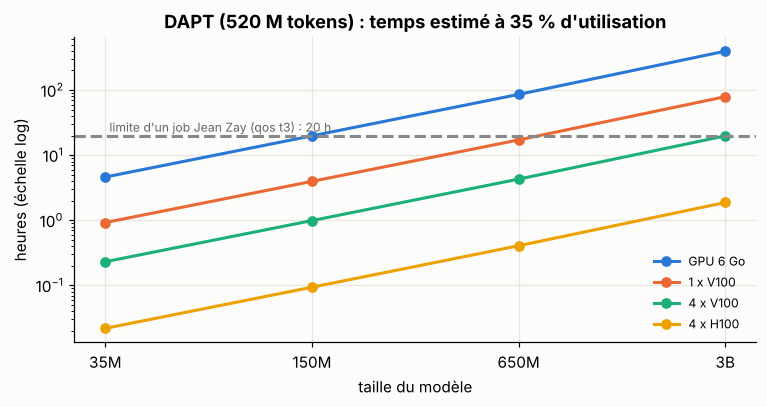

In [4]:
models = [("35M", 35e6), ("150M", 150e6), ("650M", 650e6), ("3B", 3e9)]
tokens = 2e6 * 130 * 2
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, (hw, peak, n, ck) in enumerate([("GPU 6 Go", 25, 1, True), ("1 x V100", 125, 1, True), ("4 x V100", 125, 4, True), ("4 x H100", 989, 4, False)]):
    ax.plot([m for m, _ in models], [hours(P, tokens, peak, n, checkpointing=ck) for _, P in models], "o-", color=PALETTE[k], label=hw)
ax.axhline(20, ls="--", color="#888"); ax.text(0.02, 23, "limite d'un job Jean Zay (qos t3) : 20 h", fontsize=8, color="#666")
ax.set_yscale("log"); ax.set_ylabel("heures (échelle log)"); ax.set_xlabel("taille du modèle")
ax.set_title("DAPT (520 M tokens) : temps estimé à 35 % d'utilisation"); ax.legend(fontsize=8)
plt.show()

Deux conséquences concrètes. D'abord, sur 4 H100, même la DAPT du 3B ne prend que **quelques heures** (environ 2 h théoriques pour ce volume) ; sur un V100, la DAPT du 650M demande déjà environ 17 h, et sur la carte de 6 Go plusieurs jours. Pour ProtAnnotML, **le calcul n'est donc pas le facteur limitant** sur Jean Zay : c'est la qualité, la déduplication et la couverture des données. Ensuite, ces chiffres sont des **bornes optimistes** : 35 % d'utilisation suppose des lots bien remplis (séquences regroupées par longueur) et une attention efficace ; avec l'implémentation standard et des séquences de longueurs très variées, 15 à 25 % est plus réaliste. Chronomètre 200 pas et extrapole avant de réserver.

## 3. Le bon réglage pour chaque machine

| | GPU 6 Go (poste) | V100 (serveur) | H100 (Jean Zay) |
|---|---|---|---|
| Rôle | test rapide, mise au point, petits modèles, inférence | affinage 650M (LoRA ou complet), ablations | DAPT, affinage complet, balayages, 3B |
| Précision | fp16 + *loss scaling* (selon la carte) | **fp16** + *loss scaling* (pas de bf16 sur V100) | **bf16** (pas de *loss scaling*), TF32 pour le reste |
| Attention | SDPA si disponible | SDPA ; pas de FlashAttention-2 (architecture trop ancienne) | SDPA / FlashAttention |
| Mémoire | checkpointing, lots de 4–8, accumulation | checkpointing pour 650M complet | lots plus grands, pas de checkpointing pour 650M |
| Astuce | `PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True` contre la fragmentation | regrouper par longueur (`group_by_length`) | données sur `$WORK`/`$SCRATCH`, cache HF local |

Le script d'affinage choisit automatiquement bf16 si le GPU le supporte, sinon fp16 avec `GradScaler` (notebook 4). Le *loss scaling* n'est pas un détail sur V100 : sans lui, les petits gradients des têtes deviennent nuls en fp16 et l'entraînement stagne sans erreur visible.

## 4. Jean Zay : scripts Slurm, nœuds hors ligne, reprise

Les règles qui comptent sur Jean Zay (à vérifier dans la documentation de l'IDRIS, elles évoluent) :
- partition H100 : `-C h100` et `module load arch/h100` **avant** les autres modules ; 4 H100 de 80 Go et 96 cœurs par nœud, donc 24 cœurs par GPU ; QoS `qos_gpu_h100-dev` (2 h), `qos_gpu_h100-t3` (20 h, par défaut), `qos_gpu_h100-t4` (100 h, peu de GPU) ;
- V100 : `-C v100-32g` (ou `v100-16g`), 4 GPU et 40 cœurs par nœud, donc 10 cœurs par GPU ; QoS `qos_gpu-dev`, `qos_gpu-t3`, `qos_gpu-t4` ;
- le compte d'heures est indiqué avec `--account=<projet>@h100` ou `@v100` (vérifie le nom exact avec `idracct`) ;
- les **nœuds de calcul n'ont pas accès à Internet** : télécharger modèles et données **avant**, depuis une frontale, dans `$WORK`, et lancer les jobs avec `HF_HUB_OFFLINE=1` ;
- le temps par défaut est court (10 min) : toujours préciser `--time`.

Le script ci-dessous lance un processus par GPU avec `srun` (le script d'entraînement lit `SLURM_PROCID` et `SLURM_LOCALID`), demande à Slurm d'envoyer `SIGUSR1` 5 minutes avant la limite (le script sauve alors un checkpoint et s'arrête proprement, de façon synchronisée entre GPU), et une chaîne de jobs dépendants reprend automatiquement depuis `last.pt`.

In [5]:
SLURM = {
"slurm/h100_train.slurm": """#!/bin/bash
#SBATCH --job-name=protannot-h100
#SBATCH --account=CHANGE_ME@h100          # your project, check with: idracct
#SBATCH -C h100
#SBATCH --nodes=1
#SBATCH --ntasks-per-node=4               # one task per GPU
#SBATCH --gres=gpu:4
#SBATCH --cpus-per-task=24                # 96 cores / 4 GPUs
#SBATCH --hint=nomultithread
#SBATCH --time=20:00:00
#SBATCH --qos=qos_gpu_h100-t3
#SBATCH --signal=USR1@300                 # SIGUSR1 to every task 5 min before the time limit
#SBATCH --output=logs/%x-%j.out

set -euo pipefail
module purge
module load arch/h100                      # must come first on the H100 partition
module load pytorch-gpu/py3/CHANGE_ME      # pick a version: module avail pytorch-gpu
export HF_HOME=$WORK/hf_cache HF_HUB_OFFLINE=1 TOKENIZERS_PARALLELISM=false
export MASTER_ADDR=$(scontrol show hostnames "$SLURM_JOB_NODELIST" | head -n 1) MASTER_PORT=29500
cd $WORK/projet_protannotml
srun python scripts/train_multitask.py --config configs/h100.yaml
""",
"slurm/v100_train.slurm": """#!/bin/bash
#SBATCH --job-name=protannot-v100
#SBATCH --account=CHANGE_ME@v100
#SBATCH -C v100-32g
#SBATCH --nodes=1
#SBATCH --ntasks-per-node=1
#SBATCH --gres=gpu:1
#SBATCH --cpus-per-task=10                # 40 cores / 4 GPUs
#SBATCH --hint=nomultithread
#SBATCH --time=20:00:00
#SBATCH --qos=qos_gpu-t3
#SBATCH --signal=USR1@300
#SBATCH --output=logs/%x-%j.out

set -euo pipefail
module purge
module load pytorch-gpu/py3/CHANGE_ME
export HF_HOME=$WORK/hf_cache HF_HUB_OFFLINE=1 TOKENIZERS_PARALLELISM=false
cd $WORK/projet_protannotml
srun python scripts/train_multitask.py --config configs/v100.yaml
""",
"slurm/h100_dapt.slurm": """#!/bin/bash
#SBATCH --job-name=protannot-dapt
#SBATCH --account=CHANGE_ME@h100
#SBATCH -C h100
#SBATCH --nodes=1
#SBATCH --ntasks-per-node=1               # torchrun spawns one process per GPU
#SBATCH --gres=gpu:4
#SBATCH --cpus-per-task=96
#SBATCH --hint=nomultithread
#SBATCH --time=20:00:00
#SBATCH --qos=qos_gpu_h100-t3
#SBATCH --output=logs/%x-%j.out

set -euo pipefail
module purge
module load arch/h100
module load pytorch-gpu/py3/CHANGE_ME
export HF_HOME=$WORK/hf_cache HF_HUB_OFFLINE=1 TOKENIZERS_PARALLELISM=false
cd $WORK/projet_protannotml
srun torchrun --standalone --nproc_per_node=4 scripts/dapt_mlm.py \\
    --model facebook/esm2_t33_650M_UR50D --train data/ig_train.txt --valid data/ig_valid.txt \\
    --out runs/dapt650M --batch 64 --max_steps 60000
""",
"slurm/chain.sh": """#!/bin/bash
# Submit N dependent jobs: each one resumes from the last checkpoint of the previous one.
# Usage: bash slurm/chain.sh slurm/h100_train.slurm 3
set -euo pipefail
script=$1; n=${2:-3}
jid=$(sbatch --parsable "$script"); echo "submitted $jid"
for i in $(seq 2 "$n"); do
  jid=$(sbatch --parsable --dependency=afterany:"$jid" "$script"); echo "submitted $jid (after previous)"
done
""",
"slurm/prefetch_models.sh": """#!/bin/bash
# Run on a Jean Zay login node (internet access), NOT in a job: fills the local Hugging Face cache.
set -euo pipefail
export HF_HOME=$WORK/hf_cache
for m in facebook/esm2_t12_35M_UR50D facebook/esm2_t30_150M_UR50D facebook/esm2_t33_650M_UR50D; do
  python -c "from transformers import AutoTokenizer, EsmForMaskedLM; AutoTokenizer.from_pretrained('$m'); EsmForMaskedLM.from_pretrained('$m')"
done
du -sh $HF_HOME
""",
}
for rel, text in SLURM.items():
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(text)
print(sorted(str(p.relative_to(ROOT)) for p in (ROOT / "slurm").iterdir()))

['slurm/chain.sh', 'slurm/h100_dapt.slurm', 'slurm/h100_train.slurm', 'slurm/prefetch_models.sh', 'slurm/v100_train.slurm']


> 🔁 **Reprise** : quand un job reçoit `SIGUSR1`, toutes les tâches décident **ensemble** de s'arrêter au même pas (réduction `MAX` du drapeau), le rang 0 écrit `last.pt` de façon atomique, puis le job suivant de la chaîne reprend à l'époque sauvegardée. L'époque interrompue est rejouée depuis son début : un léger gaspillage, mais un code de reprise beaucoup plus simple et sûr.

## 5. Reproductibilité

Ce qu'un relecteur (ou toi, dans six mois) doit pouvoir retrouver pour chaque chiffre de l'article :

| Élément | Comment |
|---|---|
| Données | version de la release IMGT, script d'extraction, empreinte (hash) des fichiers, fiche de jeu de données |
| Découpage | `splits.json` versionné, seuil et méthode de clustering |
| Code | commit git (écrit dans le dossier du run), `requirements.txt` avec versions **figées** |
| Configuration | le YAML complet copié dans le dossier du run (fait par le script) |
| Aléa | graine (`seed`) ; plusieurs graines pour les résultats principaux |
| Matériel | type et nombre de GPU, précision (bf16/fp16), temps total |
| Journal | `log.jsonl` (pertes, poids de tâches, validation) ; si tu utilises W&B sur Jean Zay : `WANDB_MODE=offline` puis `wandb sync` depuis une frontale |

In [6]:
(ROOT / "requirements.txt").write_text("""# Pin exact versions after your first working install: pip freeze > requirements.lock
torch>=2.3
transformers>=4.45
peft>=0.12
datasets>=2.20
accelerate>=0.33
pyyaml>=6.0
numpy>=1.26
scipy>=1.11
pandas>=2.1
scikit-learn>=1.4
matplotlib>=3.8
fastapi>=0.110
uvicorn>=0.29
""")
print((ROOT / "requirements.txt").read_text())

# Pin exact versions after your first working install: pip freeze > requirements.lock
torch>=2.3
transformers>=4.45
peft>=0.12
datasets>=2.20
accelerate>=0.33
pyyaml>=6.0
numpy>=1.26
scipy>=1.11
pandas>=2.1
scikit-learn>=1.4
matplotlib>=3.8
fastapi>=0.110
uvicorn>=0.29



## 6. Livrer l'outil : ligne de commande, service, sortie AIRR

Pour être adopté, l'outil doit parler le langage de ses utilisateurs : une **ligne de commande** qui lit un FASTA, et une sortie **tabulaire compatible AIRR** (colonnes `sequence_id`, `locus`, `v_call`, `fwr1_aa`, `cdr1_aa`, …, `cdr3_aa`, `fwr4_aa`), plus la numérotation IMGT complète en JSON. Les colonnes AIRR permettent de comparer directement avec une sortie d'IMGT/HighV-QUEST.

In [ ]:
"""Annotate a FASTA file with a trained ProtAnnotML run; writes an AIRR-like TSV (one row per domain).

Usage: python scripts/annotate.py --run runs/h100 --fasta input.fasta --out annotations.tsv [--device cuda]
"""
import argparse
import csv
import json
import sys
from pathlib import Path

import torch
import yaml
from transformers import AutoTokenizer

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
from protannotml.inference import annotate                     # noqa: E402
from protannotml.labels import LabelSpace                       # noqa: E402
from protannotml.model import ProtAnnotModel                    # noqa: E402

REGION_COLUMNS = [("FR1", "fwr1_aa"), ("CDR1", "cdr1_aa"), ("FR2", "fwr2_aa"), ("CDR2", "cdr2_aa"),
                  ("FR3", "fwr3_aa"), ("CDR3", "cdr3_aa"), ("FR4", "fwr4_aa")]


def read_fasta(path):
    name, chunks = None, []
    for line in open(path):
        line = line.strip()
        if line.startswith(">"):
            if name is not None:
                yield name, "".join(chunks)
            name, chunks = line[1:].split()[0], []
        elif line:
            chunks.append(line.upper())
    if name is not None:
        yield name, "".join(chunks)


def load_run(run_dir, device):
    run = Path(run_dir)
    cfg = yaml.safe_load(open(run / "config.yaml"))
    space = LabelSpace.load(run / "label_space.json")
    model = ProtAnnotModel(space.sizes(), backbone=cfg["backbone"])
    if cfg.get("lora", False):
        from peft import LoraConfig, get_peft_model
        model.backbone = get_peft_model(model.backbone, LoraConfig(r=cfg["lora_r"], lora_alpha=cfg["lora_alpha"],
                                                                   target_modules=["query", "key", "value", "dense"]))
    state = torch.load(run / "last.pt", map_location="cpu", weights_only=False)["model"]
    model.load_state_dict(state)
    return model.to(device).eval(), AutoTokenizer.from_pretrained(cfg["backbone"]), space


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--run", required=True); ap.add_argument("--fasta", required=True); ap.add_argument("--out", required=True)
    ap.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    ap.add_argument("--batch", type=int, default=32); ap.add_argument("--gene_threshold", type=float, default=0.5)
    args = ap.parse_args()
    model, tok, space = load_run(args.run, args.device)
    records = sorted(read_fasta(args.fasta), key=lambda r: len(r[1]))         # length-sorted batches: less padding
    fields = ["sequence_id", "domain_index", "domain_type", "start", "end", "locus", "species", "v_call",
              "v_call_candidates"] + [c for _, c in REGION_COLUMNS] + ["imgt_numbering"]
    with open(args.out, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=fields, delimiter="\t")
        w.writeheader()
        for k in range(0, len(records), args.batch):
            chunk = records[k:k + args.batch]
            results = annotate(model, tok, [s for _, s in chunk], space, device=args.device, gene_threshold=args.gene_threshold)
            for (name, _), res in zip(chunk, results):
                for i, d in enumerate(res["domains"]):
                    row = dict(sequence_id=name, domain_index=i, domain_type=d["type"], start=d["start"] + 1, end=d["end"])
                    if d["type"] == "V":
                        regions = {r: "" for r, _ in REGION_COLUMNS}
                        for aa, r in zip(d["sequence"], d["regions"]):
                            regions[r] += aa
                        row.update(locus=d["locus"], species=d["species"], v_call=(d["gene"] or "").split("|")[-1],
                                   v_call_candidates=json.dumps(d["gene_candidates"]),
                                   imgt_numbering=json.dumps(list(zip(d["imgt_positions"], d["sequence"]))),
                                   **{col: regions[r] for r, col in REGION_COLUMNS})
                    w.writerow(row)
    print(f"annotated {len(records)} sequences -> {args.out}")


if __name__ == "__main__":
    main()

Un service web minimal, pour une interface ou pour d'autres outils (y compris un agent via MCP, module 15) :

In [ ]:
"""Minimal HTTP service. Run: PROTANNOT_RUN=runs/h100 uvicorn serve:app --app-dir scripts --port 8000"""
import os
import sys
from pathlib import Path

import torch
from fastapi import FastAPI
from pydantic import BaseModel, Field

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
sys.path.insert(0, str(Path(__file__).resolve().parent))
from annotate import load_run                                 # noqa: E402
from protannotml.inference import annotate                    # noqa: E402

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL, TOK, SPACE = load_run(os.environ["PROTANNOT_RUN"], DEVICE)
app = FastAPI(title="ProtAnnotML", version="0.1.0")


class AnnotateRequest(BaseModel):
    sequences: list[str] = Field(..., max_length=256, description="protein sequences (one-letter code)")
    gene_threshold: float = 0.5


@app.post("/annotate")
def annotate_endpoint(req: AnnotateRequest):
    seqs = [s.strip().upper() for s in req.sequences]
    return annotate(MODEL, TOK, seqs, SPACE, device=DEVICE, gene_threshold=req.gene_threshold)


@app.get("/health")
def health():
    return {"status": "ok", "device": DEVICE, "genes": len(SPACE.genes)}

## 7. Fiche de modèle et organisation du projet

Une fiche de modèle (*model card*) dit ce que le modèle sait faire, sur quelles données, et **où il ne faut pas lui faire confiance**. Pour un outil d'annotation diffusé par IMGT, c'est aussi ce qui protège la réputation de la base.

In [7]:
(ROOT / "MODEL_CARD.md").write_text("""# ProtAnnotML — model card (template)

## Intended use
Annotation of immunoglobulin and T cell receptor protein sequences: domain delimitation (V, C), IMGT unique
numbering of V domains, FR-IMGT / CDR-IMGT delimitation, locus / species / V gene identification with abstention.
Not intended for: non-IG/TR proteins, clinical decisions, sequences outside the training species without checking.

## Training data
IMGT release: <version, date>. Sources: <IMGT/LIGM-DB, IMGT/HighV-QUEST outputs, IMGT/mAb-DB>, filters: <...>.
Number of sequences per locus and species: <table>. Known biases: <naive repertoires over-represented, species coverage>.

## Evaluation
Regimes: homology-aware split (germline clusters at <x>% identity), held-out species <...>, temporal split on IMGT/mAb-DB.
Metrics (95% cluster-bootstrap CI): per-residue and per-domain numbering accuracy, CDR boundary errors,
gene identification with risk-coverage curve. Reference method: IMGT/DomainGapAlign on the same test sequences.

## Limitations
- Gene/allele calls are only defined for genes present in training; below the confidence threshold the model abstains.
- Unusual formats (e.g. <...>) were not seen in training.
- Labels derive partly from alignment-based annotation; an expert-curated test set is reported separately.

## Technical details
Backbone: <ESM-2 650M>, DAPT on <corpus>, multitask fine-tuning (uncertainty weighting), constrained decoding.
Hardware: <4 x H100, Jean Zay>, training time <h>, inference <ms/sequence on GPU / CPU>.
""")

(ROOT / "README.md").write_text("""# projet_protannotml

Code of the ProtAnnotML capstone (course notebooks pf01-pf06). The `protannotml/` package is exported from the notebooks.

~~~
protannotml/   imgt.py (numbering, IMGT/AIRR readers) · synth.py (synthetic data) · splits.py · align.py (alignment baseline)
               features.py · decode.py (constrained Viterbi) · stats.py (evaluation) · labels.py · crf.py · model.py
               data.py · inference.py
scripts/       make_synthetic_data.py · smoke_test.py · dapt_mlm.py · train_multitask.py · annotate.py · serve.py
configs/       gpu6gb.yaml · v100.yaml · h100.yaml
slurm/         h100_train.slurm · v100_train.slurm · h100_dapt.slurm · chain.sh · prefetch_models.sh
~~~

Quick start (any machine with PyTorch):

~~~bash
pip install -r requirements.txt
python scripts/make_synthetic_data.py          # writes data_protannotml/ (fictional sequences)
python scripts/smoke_test.py                   # 1-2 min on CPU, must print SMOKE TEST PASSED
python scripts/train_multitask.py --config configs/gpu6gb.yaml --override epochs=1
~~~

Jean Zay: run `slurm/prefetch_models.sh` on a login node, then `bash slurm/chain.sh slurm/h100_train.slurm 3`.
Replace every `CHANGE_ME` (account, module version) first.
""")
print(sorted(p.name for p in ROOT.iterdir()))

['MODEL_CARD.md', 'README.md', 'configs', 'protannotml', 'requirements.txt', 'scripts', 'slurm']


Enfin, le script qui régénère les données synthétiques **dans le dossier du projet** (le même code que les notebooks 1–2, sans les figures), pour que `configs/*.yaml` trouvent leurs fichiers :

In [ ]:
"""Regenerate the synthetic development data (notebooks pf01-pf02) into data_protannotml/ of the project.

Usage (from projet_protannotml/): python scripts/make_synthetic_data.py [--n 6000]
"""
import argparse
import json
import sys
from pathlib import Path

import numpy as np

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
from protannotml.imgt import allele_key                                                     # noqa: E402
from protannotml.splits import cluster_at, encode_aligned, group_split, identity_matrix      # noqa: E402
from protannotml.synth import equivalence_sets, make_dataset, make_reference, save_jsonl, check_example  # noqa: E402


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--n", type=int, default=6000)
    ap.add_argument("--out", default="data_protannotml")
    args = ap.parse_args(argv)
    out = Path(args.out); out.mkdir(exist_ok=True)
    refs, js, cs = make_reference(seed=0)
    data = make_dataset(refs, js, cs, n=args.n, seed=1)
    assert all(check_example(e) for e in data)
    eq_a, eq_g = equivalence_sets(refs, "allele"), equivalence_sets(refs, "gene")
    for e in data:
        for d in e["domains"]:
            if d["type"] == "V":
                k = allele_key(d["species"], d["v_allele"])
                d["allele_set"], d["gene_set"] = sorted(eq_a[k]), sorted(eq_g[k])
    keys = [allele_key(r["species"], r["allele"]) for r in refs]
    _, labels = cluster_at(identity_matrix(encode_aligned([r["positions"] for r in refs])), 0.80)
    cluster_of = dict(zip(keys, labels))
    rng = np.random.default_rng(0)
    ids = [e["id"] for e in data]; rng.shuffle(ids); n = len(ids)
    splits = {"R0 aléatoire": {"train": ids[: int(0.8 * n)], "val": ids[int(0.8 * n): int(0.9 * n)], "test": ids[int(0.9 * n):], "dropped": []},
              "R1 par allèle": group_split(data, lambda d: allele_key(d["species"], d["v_allele"]), seed=0),
              "R2 cluster 80 %": group_split(data, lambda d: int(cluster_of[allele_key(d["species"], d["v_allele"])]), seed=0)}
    rest = [e["id"] for e in data if e["species"] != "Mus musculus"]; rng.shuffle(rest)
    splits["R3 espèce exclue"] = {"train": rest[: int(0.9 * len(rest))], "val": rest[int(0.9 * len(rest)):],
                                  "test": [e["id"] for e in data if e["species"] == "Mus musculus"], "dropped": []}
    save_jsonl(data, out / "examples.jsonl"); save_jsonl(refs, out / "reference_V.jsonl")
    save_jsonl(js, out / "reference_J.jsonl"); save_jsonl(cs, out / "reference_C.jsonl")
    (out / "splits.json").write_text(json.dumps(splits))
    print(f"wrote {len(data)} examples and {len(splits)} split regimes to {out}/")


if __name__ == "__main__":
    main()

On l'exécute ici pour vérifier qu'il fonctionne de bout en bout, puis on vérifie que tous les fichiers Python du projet compilent :

In [8]:
import subprocess, py_compile
r = subprocess.run([sys.executable, "scripts/make_synthetic_data.py", "--n", "600", "--out", "/tmp/protannot_check"],
                   cwd=ROOT, capture_output=True, text=True)
print(r.stdout.strip() or r.stderr[-800:])
for f in sorted(ROOT.rglob("*.py")):
    py_compile.compile(str(f), doraise=True)
print("all", len(list(ROOT.rglob('*.py'))), "Python files compile")

wrote 600 examples and 4 split regimes to /tmp/protannot_check/
all 19 Python files compile


## 8. Récapitulatif

| Question | Réponse rapide |
|---|---|
| Ça tient en mémoire ? | ~16 o/paramètre en affinage complet + activations ; LoRA ≈ poids gelés + activations ; mesurer le pic réel |
| Combien de temps ? | $6ND$ (ou $8ND$ avec checkpointing) / (pic × MFU × nb GPU) ; chronométrer 200 pas |
| Quelle machine ? | 6 Go : test et petits modèles ; V100 : fp16, 650M LoRA/complet ; H100 : bf16, DAPT et gros modèles |
| Jean Zay | `-C h100` + `arch/h100`, compte `@h100`, pas d'Internet, `--signal`, chaînes de jobs |
| Reproductible ? | release IMGT, splits, commit, YAML, graines, matériel, journaux |
| Livrable | CLI FASTA → TSV AIRR, service HTTP, fiche de modèle |

### 🏋️ Exercices

1. **Mesure contre estimation.** Sur ta carte de 6 Go, lance 50 pas de `gpu6gb.yaml` et compare `torch.cuda.max_memory_allocated()` à l'estimation de la section 1. Ajuste le coefficient 34 si besoin.
2. **Chronométrage.** Sur le V100, mesure le débit (résidus/s) en fp16 avec et sans `group_by_length`, puis estime le temps d'une DAPT complète.
3. **Interopérabilité.** Annote 200 séquences avec `scripts/annotate.py` et compare colonne par colonne avec la sortie AIRR d'IMGT/HighV-QUEST (`fwr1_aa`…`fwr4_aa`). Où sont les désaccords ?
4. **MCP.** Expose `/annotate` comme outil MCP (module 15) pour qu'un agent puisse annoter une séquence au cours d'une conversation, et combine-le avec le serveur SPARQL d'IMGT/mAb-KG (module 21).

<details><summary>Indications</summary>

1. L'écart vient souvent des tampons temporaires (logits de la tête positions : $b \times s \times 158$ en float32) et de la fragmentation.
3. Commence par les séquences où les deux outils sont d'accord sur la germline : les désaccords restants sont des questions de numérotation ou de bornes, les plus faciles à analyser.
</details>